# Title

## Imports

In [316]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as cm
import random
from scipy.stats import norm
import pandas as pd

## Data Generation functions

In [317]:
# Data Generation Functions
# True underlying function g(x) = sin²(2πx)
def g(x) :
    """
        This method computes the true underlying function g(x) = sin²(2πx).

        Arguments:
            x (float): input value in range [0,1].
        Return:
            np.array : true function value g(x).
    """
    return np.sin(2 * np.pi *x) ** 2


# Generates N samples from g(x) with Guassian noise variance σ = 0.07
def gen_data(N) :
    """
        This method generates N samples from g(x) with Gaussian noise (sigma = 0.07).

        Arguments:
            N (int): number of points to generate.
        Return:
            xdata (list[float]): list containing x1,...,xN.
            ydata (list[float]): list containing y1,...,yN.
    """
    ydata = []
    xdata = []
    for i in range(N) :
        rand = random.uniform(0,1)
        xdata.append(rand) #Sample random Gaussisan noise from N ~ (0, 0.07^2)
        rande = random.uniform(0,1)
        epsilon = norm.ppf(rande, loc=0, scale=0.07)
        ydata.append(g(rand) + epsilon)
    return xdata, ydata


## Basis Functions

In [318]:
# Basis Functions
# Return polynomial basis matrix with powers 0 to k-1
def poly_basis (x,k) :
    """
        This method builds a polynomial basis matrix with powers 0 to k-1.

        Arguments:
            x : input values
            k (int): number of basis functions.
        Return:
           np.array: array containing polynomial basis matrix with powers 0 to k-1
    """
    return np.column_stack([np.asarray(x) ** i for i in range(k)]) #Stack columns [x^0, x^1,..., x^(k-1)]

# Return sin basis matrix, sin(iπx), for i from 1 to k
def sin_basis (x,k) :
    """
        This method builds a sin basis matrix, sin(iπx), for i from 1 to k

        Arguments:
            x : input values.
            k (int): number of basis functions.
        Return:
            np.array: matrix with columns sin(πx), sin(2πx), …, sin(kπx).
    """
    return np.column_stack([np.sin((i+1)*np.pi*np.asarray(x)) for i in range(k)]) #Stack columns [sin(pix), sin(2pix), ..., sin(kpix)]


## Linear regression Solvers

In [319]:
# Linear Regression Functions
# Solves least squares equation, y = θw, returns weights w
def lin_reg_sol (theta, y) :
    """
        This method solves least squares equation, y = θw using least squares.

        Arguments:
            theta (np.array): desgin matrix.
            y (np.array): y value vector.
        Return:
            w (np.array): array containing estimated weights vector w.
    """
    # return np.linalg.inv(theta.T@theta)@theta.T@y
    #Solved using numpy instead of inverse
    w, *_ = np.linalg.lstsq(theta, y, rcond=None)
    return w


# Fits a single polynomial model degree k and returns weights, predictions and MSE
def lin_reg_sol_k(x,y,k, basis_func=poly_basis, w=None) :
    """
        This method fits linear regression model for a single model of degree k

        Arguments:
            x : x input data.
            y : y input data.
            k (int): model degree / complexity (number of basis functions.
            basis_func (callable, optional): basis function used to make design matrix in model.
            w (np.array, optional): precomputed weight vector for prediction only
        Return:
            list : [w, y_hat, mse]
                w (np.array): array containing estimated weights vector w.
                y_hat (np.array): array containing predicted y vector.
                mse (float): mean squared error of predicted y vector.
    """
    # theta = poly_basis(x,k)
    theta = basis_func(x,k)
    if w is None: #No weights given so fit them
        w = lin_reg_sol(theta,y)
    y_hat = theta @ w
    mse = np.mean((y - y_hat)**2)
    return [w, y_hat, mse]


# Fits multiple polynomial models of degree k for a defined set of k values, returns weights, predictions and MSE for each model
def fit_lin_reg(xdata, ydata, k_values, basis_func=poly_basis) :
    """
        This method fits linear regression models of mulitple degrees / complexity k for a defined set of k values.

        Arguments:
            xdata : x input data.
            ydata : y input data.
            k_values (int): list of model degrees / complexities to evaluate.
            basis_func (callable, optional): basis function to use.
        Return:
            list : list of tuples (k,w,y_hat,mse) for each fitted model
    """
    results = []
    for k in k_values: #fit model for each degree k
        sol = lin_reg_sol_k(xdata, ydata, k, basis_func)
        results.append((k, sol[0], sol[1], sol[2]))
    return results


# Runs r reps of model fitting for k degrees of model, on N samples, returns the average MSE across runs
def r_sims(N, r, k_values, basis_func=poly_basis, wlist = None) :
    """
        This method runs r repetitions of model fitting to estimate the average training and test MSE .

        Arguments:
            N (int): number of samples per run.
            r (int): number of repetitions.
            k_values (list[int]): model degrees / complexities.
            basis_func (callable): basis function for model fitting.
            wlist (list[np.array], optional): precomputed model weights for test runs
        Return:
            df (pd.DataFrame): mean MSEs for each k
            results_weights (np.array): weight vectors for each run
    """
    results=[]
    results_weights=[]
    for i in range(r):
        xdata, ydata = gen_data(N)
        if wlist is None: #No weights given so compute training mse and weights for each run
            lm = fit_lin_reg(xdata, ydata, k_values, basis_func)
            mse = []
            weights=[]
            for j in lm:
                mse.append(j[3])
                weights.append(j[1])
        else: #Weigths given so computing test mse on new samples
            mse = []
            weights = wlist[i]
            for k, w in zip(k_values, weights) :
                lmtest = lin_reg_sol_k(xdata, ydata, k, basis_func, w=w)
                mse.append(lmtest[2])

        results.append(mse)
        results_weights.append(weights)
    avgmse = [0] * len(k_values)

    for i in range(len(k_values)): #Average mse across r runs
        total = 0
        for j in range(r) :
            total += results[j][i]
        avgmse[i] = total/r

    df = pd.DataFrame({'k' : k_values, 'avg_mse' : avgmse})
    return df, results_weights


## Plotting Functions

In [320]:
# Plotting Functions
# Plots data points and fitted regression curves. Has the option to also plot the true function
def plot_models(xdata, ydata, results, xmin, xmax, ymin, ymax, colormap='tab10' , truFunc = None, basis_func=poly_basis, basis_name=None) :
    """
        This method plots data points and fitted regression models for different model degrees / complexities k

        Arguments:
            xdata : x training data.
            ydata : y training data
            results (int): list of (k,w,y_hat,mse) for each fitted model.
            xmin, xmax, ymin, ymax (float): axis limits
            colormap (str, optional): colours for the plots using matplotlib
            truFunc (callable, optional): true funciton to also plot if given
            basis_func (callable, optional): basis function used for model fitting
            basis_name (str, optional): name of the basis used in model fitting for title
        Return:
            fig (matplotlib.figure.Figure): figure generated
            ax (matplotlib.axes.Axes): plot axis
    """
    if basis_name is None: #find basis name from function name
        basis_name = basis_func.__name__.replace('_basis','').capitalize()

    x_points = np.linspace(xmin, xmax, 100)
    fig, ax = plt.subplots()

    ax.scatter(xdata, ydata, color='black', label='data', s=10)

    cmap = getattr(cm, colormap) #Give each model a differnt colour
    colours = cmap(np.linspace(0.38, 1, len(results)))

    for (k, w, _, _), colour in zip(results, colours): #compute predicted curve for model of degree k
        theta_points = basis_func(x_points, k)
        y_points = theta_points @ w
        ax.plot(x_points, y_points, color=colour, label=f'k = {k}', linewidth=0.8)

    if truFunc is not None: #if true function is given plot it
        ax.plot(x_points, truFunc(x_points), color='black', linewidth=1)
    ax.set_ylim(ymin, ymax)

    ax.spines['left'].set_position('zero')
    ax.spines['bottom'].set_position('zero')
    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(axis='both', direction='inout', length=4)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.tick_params(which='minor', length=2)

    ax.grid(True, linestyle=':', linewidth=0.5)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'{basis_name} basis model of degree k')
    ax.legend()
    return fig, ax


# Plots ln(MSE) vs model degree k for sample size N and reps r
def plot_mse(k, mse, N, r, basis_func=poly_basis, basis_name=None, datatype='training') :
    """
        This method Plots ln(MSE) vs model degree k for training and test data.

        Arguments:
            k (list[int]): model degrees / complexities.
            mse (list[float]): MSE corresponding to each k.
            N (int): number of samples used.
            r (int): number of repetitions averaged over.
            basis_func (callable, optional): basis function used for model fitting
            basis_name (str, optional): name of the basis used in model fitting for title
            datatype (str, optional): 'training' or 'test' to add to the title
        Return:
            fig (matplotlib.figure.Figure): figure generated
            ax (matplotlib.axes.Axes): plot axis
    """
    if basis_name is None: #find basis name from function name
        basis_name = basis_func.__name__.replace('_basis','').capitalize()

    fig, ax = plt.subplots()
    #plot mse vs model degree k
    ax.plot(k, mse, color='black', linewidth=0.8)

    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(axis='both', direction='inout', length=4)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.tick_params(which='minor', length=2)

    ax.grid(True, linestyle=':', linewidth=0.5)
    ax.set_xlabel('k')
    ax.set_ylabel('ln(mse)')
    ax.set_title(f'Natural log of the {datatype} error vs the {basis_name.lower()} dimensions k, N={N}, r={r}')
    return fig, ax

# Main Questions

## Question 1

### Load Data

In [321]:
xdata = np.array([1, 2, 3, 4])
ydata = np.array([3, 2, 0, 5])
print(f'X = {xdata}')
print(f'y = {ydata}')

X = [1 2 3 4]
y = [3 2 0 5]


### Q1.a - Naive Regression

k     w0        w1        w2        w3        MSE
1     2.5000       nan       nan       nan          3.25
2     1.5000    0.4000       nan       nan          3.05
3     9.0000   -7.1000    1.5000       nan           0.8
4    -5.0000   15.1667   -8.5000    1.3333    6.9806e-27


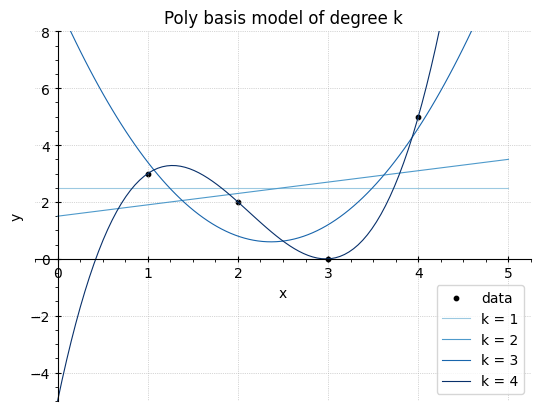

In [322]:
k_values = [1,2,3,4]
lm = fit_lin_reg(xdata, ydata, k_values)
fig, ax = plot_models(xdata, ydata, lm, 0, 5, -5, 8, colormap='Blues')
print("k     w0        w1        w2        w3        MSE")
for k, w, _, mse in lm:
    padded = np.pad(w, (0, 4 - len(w)), 'constant', constant_values=np.nan)
    print(f"{k:<2}  "
          f"{padded[0]:>8.4f}  "
          f"{padded[1]:>8.4f}  "
          f"{padded[2]:>8.4f}  "
          f"{padded[3]:>8.4f}  "
          f"{mse:>12.5g}")

## Question 2

### Load Data

In [323]:
xdata, ydata = gen_data(30)

### Q2.a.i

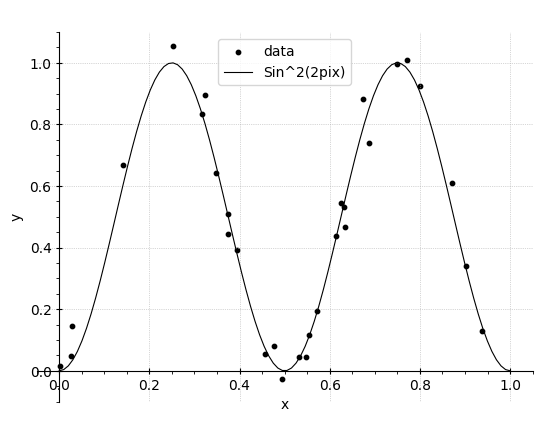

In [324]:
x_points = np.linspace(0,1,100)
fig, ax = plt.subplots()

ax.scatter(xdata, ydata, color='black', label='data', s=10)

ax.plot(x_points,g(x_points), color = 'black' ,label='Sin^2(2pix)', linewidth=0.8)

ax.set_ylim(-0.1, 1.1)

ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', direction='inout', length=4)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
ax.tick_params(which='minor', length=2)

ax.grid(True, linestyle=':', linewidth=0.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(' ')
ax.legend()

### Q2.a.ii

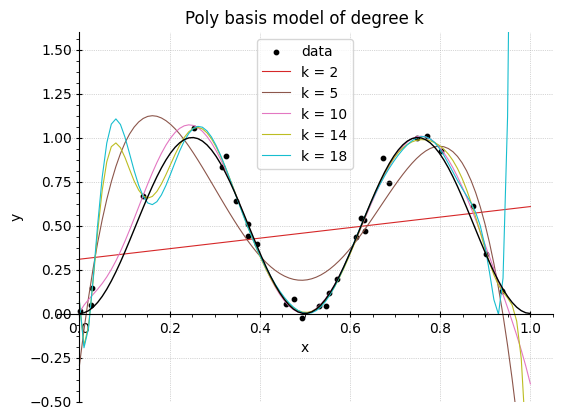

In [325]:
k_values = [2,5,10,14,18]
lm = fit_lin_reg(xdata, ydata, k_values)
fig, ax = plot_models(xdata, ydata, lm, 0, 1, -0.5, 1.6, truFunc = g)


### Q2.b-d Summary table

k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100
1 | 0.14404828828800811 | 0.13067465846711734 | 0.12236676874585628 | 0.13392155959128163
2 | 0.12001290271966948 | 0.16429302042022956 | 0.11741615204945337 | 0.13957860341086747
3 | 0.11918967884544777 | 0.15881965765708245 | 0.10780112756673839 | 0.139317093563925
4 | 0.1145148956366733 | 0.15907028111282578 | 0.10040390570760743 | 0.1750441101175939
5 | 0.022938702523486423 | 0.08595020933373765 | 0.03432893186762206 | 0.07243168330959623
6 | 0.02281548306575243 | 0.08433599716260269 | 0.02907827620840539 | 0.26517521620955814
7 | 0.00530033709389227 | 0.011298372283915843 | 0.0052657234238146465 | 0.052239227849464116
8 | 0.005226047015774124 | 0.011899729892262111 | 0.004754377344510296 | 0.1934402724039063
9 | 0.003391055413456014 | 0.02304172708866657 | 0.003557951958266364 | 0.19082928958068873
10 | 0.003391048877385232 | 0.023175436951979503 | 0.003377469681101308 | 1.42553038028138
11 | 0.00330919242

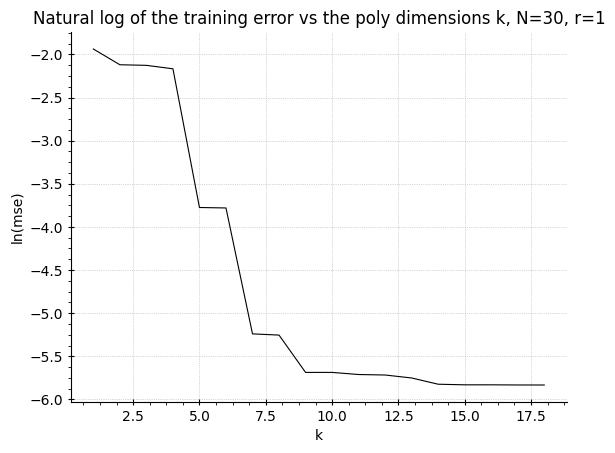

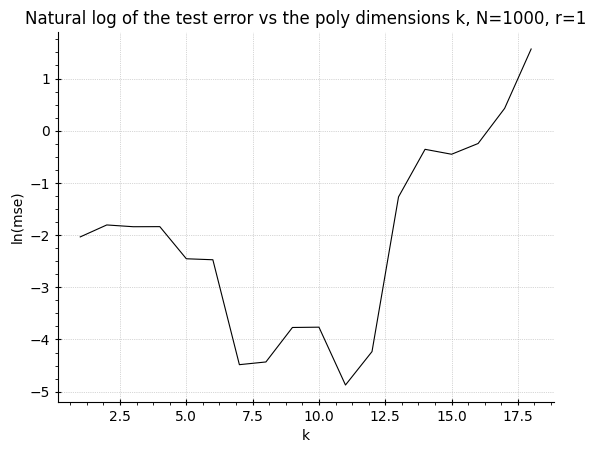

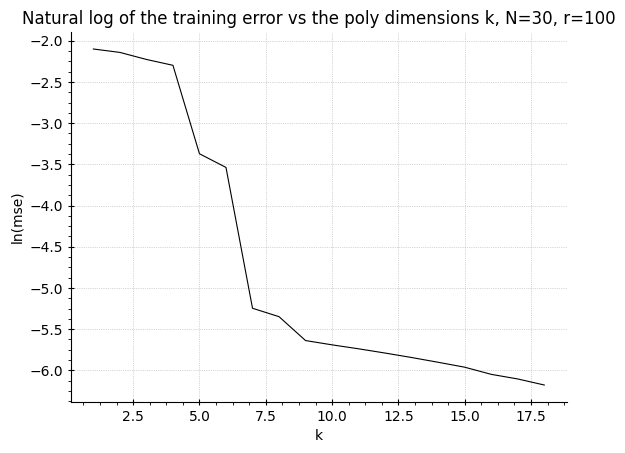

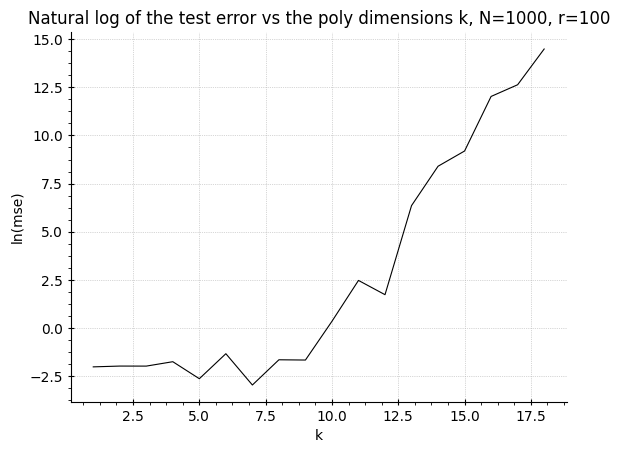

In [326]:
def experiment_Q2_b_d (smallN, largeN, r, k_values, basis_func=poly_basis):
    """
        This method does the Q2(b-d) experiments to evaluate model performance.
        Fits models on a small training dataset, evalutes test error on a large dataset and averages results over r repetitions for both training and test mse.

        Arguments:
            smallN (int): size of the training dataset.
            largeN (int): size of the large test dataset.
            r (int): number of repetitions to average over.
            k_values (list[int]): list of model degrees / complexities.
            basis_func (callable, optional): basis function to use for fitting.
        Return:
            list : list of mse results [train N=smallN, test N=largeN, avg train, avg test]
    """
    mse=[]
    #(b) Single run, N = smallN
    xdata, ydata = gen_data(smallN)
    lm = fit_lin_reg(xdata, ydata, k_values, basis_func)
    df = pd.DataFrame(lm, columns=['k', 'w', 'y_hat', 'mse'])
    mse.append(df['mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['mse']), smallN, 1, basis_func=basis_func)

    #(c) Single run (test error), N = largeN
    xtest, ytest = gen_data(largeN)
    mse_test = []
    for k, w, _, _ in lm:
        lmtest = lin_reg_sol_k(xtest, ytest, k, basis_func, w=w)
        mse_test.append(lmtest[2])
    mse.append(mse_test)
    df = pd.DataFrame({'k': k_values, 'mse': mse_test})
    fig, ax = plot_mse(df['k'], np.log(df['mse']), largeN, 1, basis_func=basis_func, datatype = 'test')

    #(d) Average results over r runs
    df, w = r_sims(smallN, r, k_values, basis_func)
    mse.append(df['avg_mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['avg_mse']), smallN, r, basis_func=basis_func)
    df, _ = r_sims(largeN, r, k_values, basis_func, wlist=w)
    mse.append(df['avg_mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['avg_mse']), largeN, r, basis_func=basis_func, datatype = 'test')

    return mse

k_values = [i for i in range(1,19)]
mse = experiment_Q2_b_d(30, 1000, 100, k_values)

print("k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100")
for k, t1, te1, t100, te100 in zip(k_values, mse[0], mse[1], mse[2], mse[3]):
    print(f"{k} | {t1} | {te1} | {t100} | {te100}")


## Question 3

k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100
1 | 0.14512626493679798 | 0.14203079635353108 | 0.14225052842061475 | 0.1574955068521224
2 | 0.1412201420049903 | 0.14810633906691095 | 0.13738145560276346 | 0.16342520881606745
3 | 0.032980505079922354 | 0.032983462666652655 | 0.028758394673885905 | 0.03524652048772096
4 | 0.03286020719857622 | 0.032740160854475314 | 0.027506325603201782 | 0.03744823140272335
5 | 0.004090862621394522 | 0.006757264432182563 | 0.005143306261258724 | 0.007314567859410421
6 | 0.004035899092079823 | 0.006977465548596646 | 0.00493452331987207 | 0.007630733482782861
7 | 0.002952033460973626 | 0.005483112077307197 | 0.003902244246972352 | 0.0066600920647181885
8 | 0.002942613986735176 | 0.005500650476496915 | 0.003677220478964234 | 0.008324496699739808
9 | 0.0029371802766054553 | 0.005614781014141044 | 0.0033766554425646318 | 0.008924015607429073
10 | 0.0029027579553984714 | 0.005644875443524407 | 0.003201517765887465 | 0.023064542818

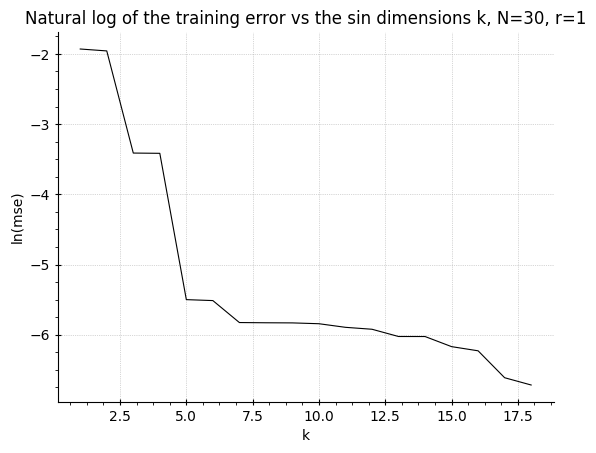

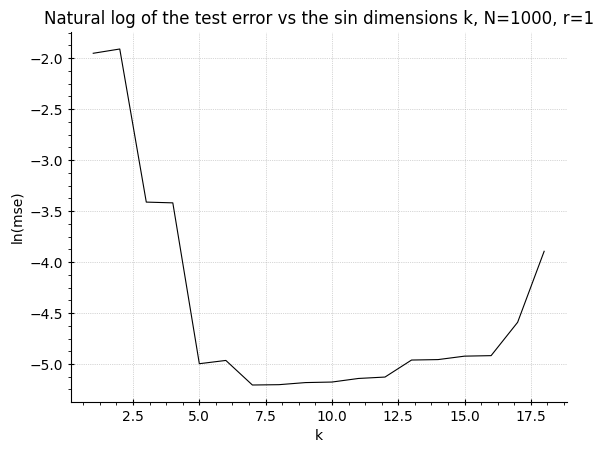

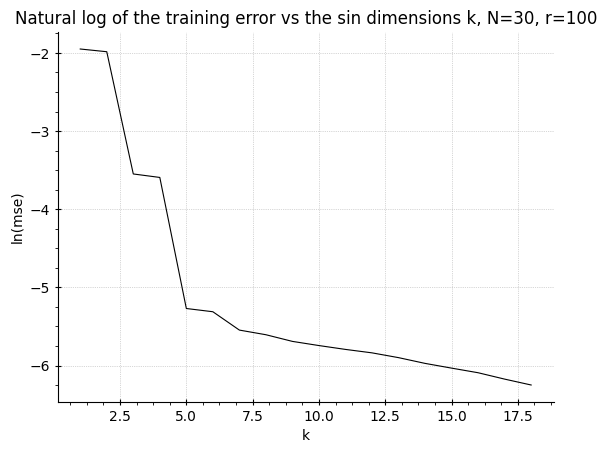

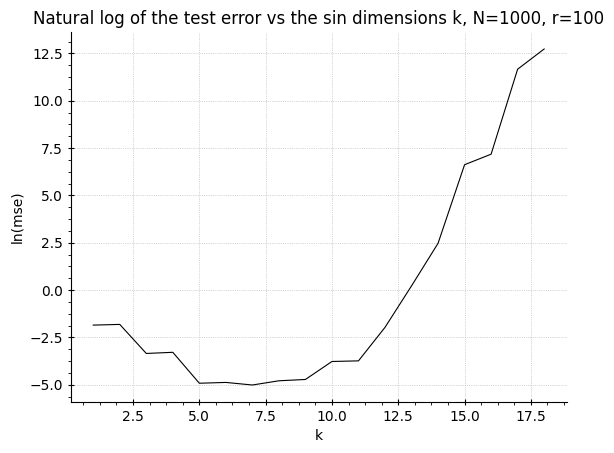

In [327]:
k_values = [i for i in range(1, 19)]
mse = experiment_Q2_b_d(30, 1000, 100, k_values, basis_func=sin_basis)

print("k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100")
for k, t1, te1, t100, te100 in zip(k_values, mse[0], mse[1], mse[2], mse[3]):
    print(f"{k} | {t1} | {te1} | {t100} | {te100}")
plt.show()
plt.close('all')